In [1]:
# importing the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
import lightkurve as lk

pd.set_option("display.max_columns", None)

c:\Users\sagal\anaconda3\envs\exoplanet\lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
#reproducibility
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

In [3]:
#read the data using pandas

tce = pd.read_csv('../dataset/q1_q17_dr24_tce_2026.11.16_11.35.38.csv', comment = '#')

In [4]:
print(tce.shape)

(20367, 155)


In [5]:
tce.head()

,kepid,tce_plnt_num,tce_rogue_flag,tce_delivname,rowupdate,tce_datalink_dvs,tce_datalink_dvr,tce_period,tce_period_err,tce_time0bk,tce_time0bk_err,tce_time0,tce_time0_err,tce_ror,tce_ror_err,tce_dor,tce_dor_err,tce_incl,tce_incl_err,tce_impact,tce_impact_err,tce_duration,tce_duration_err,tce_ingress,tce_ingress_err,tce_depth,tce_depth_err,tce_eccen,tce_eccen_err,tce_longp,tce_longp_err,tce_limbdark_mod,tce_ldm_coeff1,tce_ldm_coeff2,tce_ldm_coeff3,tce_ldm_coeff4,tce_num_transits,tce_trans_mod,tce_full_conv,tce_model_snr,tce_model_chisq,tce_model_dof,tce_robstat,tce_dof1,tce_dof2,tce_chisq1,tce_chisq2,tce_chisqgofdof,tce_chisqgof,tce_prad,tce_prad_err,tce_sma,tce_sma_err,tce_eqt,tce_eqt_err,tce_insol,tce_insol_err,tce_nkoi,tce_ioflag,tce_quarters,tce_steff,tce_steff_err,tce_slogg,tce_slogg_err,tce_smet,tce_smet_err,tce_sradius,tce_sradius_err,tce_steff_prov,tce_slogg_prov,tce_smet_prov,tce_sradius_prov,tcet_period,tcet_period_err,tcet_time0bk,tcet_time0bk_err,tcet_time0,tcet_time0_err,tcet_duration,tcet_duration_err,tcet_ingress,tcet_ingress_err,tcet_depth,tcet_depth_err,tcet_full_conv,tcet_model_chisq,tcet_model_dof,wst_robstat,wst_depth,tce_mesmedian,tce_mesmad,tce_maxmes,tce_minmes,tce_maxmesd,tce_minmesd,tce_max_sngle_ev,tce_max_mult_ev,tce_bin_oedp_stat,tce_rmesmad,tce_rsnrmes,tce_rminmes,tce_albedo,tce_albedo_err,tce_ptemp,tce_ptemp_err,tce_albedo_stat,tce_ptemp_stat,av_vf_pc,av_vf_pc_err,av_vf_afp,av_vf_afp_err,av_vf_ntp,av_vf_ntp_err,av_pp_pc,av_pp_afp,av_pp_ntp,av_training_set,av_pred_class,boot_fap,boot_mesthresh,boot_mesmean,boot_messtd,tce_cap_stat,tce_hap_stat,tce_rb_tpdur,tce_rb_tcount0,tce_rb_tcount1,tce_rb_tcount2,tce_rb_tcount3,tce_rb_tcount4,tce_fwm_stat,tce_fwm_sra,tce_fwm_sra_err,tce_fwm_sdec,tce_fwm_sdec_err,tce_fwm_srao,tce_fwm_srao_err,tce_fwm_sdeco,tce_fwm_sdeco_err,tce_fwm_prao,tce_fwm_prao_err,tce_fwm_pdeco,tce_fwm_pdeco_err,tce_dicco_mra,tce_dicco_mra_err,tce_dicco_mdec,tce_dicco_mdec_err,tce_dicco_msky,tce_dicco_msky_err,tce_dikco_mra,tce_dikco_mra_err,tce_dikco_mdec,tce_dikco_mdec_err,tce_dikco_msky,tce_dikco_msky_err
0,1162345,2,NaN,q1_q17_dr24_tce,2015-01-15,001/001162/001162345/dv/kplr001162345-002-2014...,001/001162/001162345/dv/kplr001162345-20141002...,0.831850,0.000067,132.227,0.035197,2454970.0,0.035197,0.002704,0.004213,1.022012,0.403246,25.04,243.10,0.92600,1.471,2.392,21.0000,0.04453,0.51160,6.092,2.636,0,0,0,0,claret_nonlinear_limb_darkening_model_2011,0.281886,0.984398,-0.889167,0.297218,1609,mandel-agol_geometric_transit_model,1,2.950,22280.0,26290.0,13.410,20620.0,1585,30740.0,4783.00,NaN,NaN,0.5099,0.7944,0.01877,1.007000e-06,2760.0,637.0,NaN,NaN,0,NaN,11111111111111111,6510.0,207.0,4.07,0.26,-0.24,0.30,1.728,0.791,PHO1,KIC0,KIC0,DSEP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.3090,10.90000,-6.388,0.5569,0.4381,4.959,10.410,1.097000e-03,2.416,0.2834,0.6137,NaN,NaN,NaN,NaN,NaN,NaN,0.0031,0.0027,99.4727,0.0423,0.5241,0.0423,0.0000,99.9224,0.0776,AFP,AFP,1.848600e-57,2.2715,-4.18050,0.91566,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.3430,19.418054,0.000055,36.855089,0.000807,2.2230,2.360,6.187,2.91,-0.000017,0.000014,-0.000039,0.000018,-0.055177,1.1300,0.504060,1.2900,0.507070,1.1200,-0.183490,1.2100,0.424890,1.3000,0.46282,1.1000
1,1292087,2,NaN,q1_q17_dr24_tce,2015-01-15,001/001292/001292087/dv/kplr001292087-002-2014...,001/001292/001292087/dv/kplr001292087-20141002...,1.095240,0.000010,132.133,0.002685,2454970.0,0.002685,0.005440,0.003881,3.834003,12.984626,86.17,212.40,0.25630,13.310,2.122,0.4755,0.01228,0.09518,34.530,4.427,0,0,0,0,claret_nonlinear_limb_darkening_model_2011,0.360591,0.737616,-0.567858,0.166028,1218,mandel-agol_geometric_transit_model,1,10.600,16100.0,18180.0,10.430,15520.0,1193,19800.0,2261.00,NaN,NaN,0.8916,0.6361,0.02187,1.344000e-07,2310.0,661.0,NaN,NaN,0,NaN,11111111111111111,6328.0,207.0,4.15,0.29,-0.08,0.30,1.502,0.852,PHO1,KIC0,KIC0,DSEP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.4430,5.72200,-5.308,0.6473

In [6]:
#keep all the column names to the list
tce.columns.tolist()

['kepid',
 'tce_plnt_num',
 'tce_rogue_flag',
 'tce_delivname',
 'rowupdate',
 'tce_datalink_dvs',
 'tce_datalink_dvr',
 'tce_period',
 'tce_period_err',
 'tce_time0bk',
 'tce_time0bk_err',
 'tce_time0',
 'tce_time0_err',
 'tce_ror',
 'tce_ror_err',
 'tce_dor',
 'tce_dor_err',
 'tce_incl',
 'tce_incl_err',
 'tce_impact',
 'tce_impact_err',
 'tce_duration',
 'tce_duration_err',
 'tce_ingress',
 'tce_ingress_err',
 'tce_depth',
 'tce_depth_err',
 'tce_eccen',
 'tce_eccen_err',
 'tce_longp',
 'tce_longp_err',
 'tce_limbdark_mod',
 'tce_ldm_coeff1',
 'tce_ldm_coeff2',
 'tce_ldm_coeff3',
 'tce_ldm_coeff4',
 'tce_num_transits',
 'tce_trans_mod',
 'tce_full_conv',
 'tce_model_snr',
 'tce_model_chisq',
 'tce_model_dof',
 'tce_robstat',
 'tce_dof1',
 'tce_dof2',
 'tce_chisq1',
 'tce_chisq2',
 'tce_chisqgofdof',
 'tce_chisqgof',
 'tce_prad',
 'tce_prad_err',
 'tce_sma',
 'tce_sma_err',
 'tce_eqt',
 'tce_eqt_err',
 'tce_insol',
 'tce_insol_err',
 'tce_nkoi',
 'tce_ioflag',
 'tce_quarters',
 'tce_

In [7]:
tce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20367 entries, 0 to 20366
Columns: 155 entries, kepid to tce_dikco_msky_err
dtypes: float64(132), int64(11), object(12)
memory usage: 24.1+ MB


In [8]:
#labels inspection

tce["av_training_set"].value_counts(dropna=False)

av_training_set
AFP    9596
UNK    4630
PC     3600
NTP    2541
Name: count, dtype: int64

In [9]:
#all possible labels
tce["av_training_set"].unique()

array(['AFP', 'UNK', 'PC', 'NTP'], dtype=object)

out of all the available labels we cannot use UNK labels which mean unknown the dip doesnt resemble any of the known criteria, inducing this data will cause noise and we cannot train our models on noise so we have to filter these DNK rows out.

In [10]:
tce = tce[
    tce["av_training_set"].isin(
        ["PC", "AFP", "NTP"]
    )
].copy()


In [11]:
tce.shape

(15737, 155)

Label encoding of the target variable where the PC->1, rest are 0

In [12]:
tce["planet"] = (
    tce["av_training_set"] == "PC"
).astype(int)

tce[["av_training_set", "planet"]].head(10)

,av_training_set,planet
0,AFP,0
3,AFP,0
5,PC,1
6,NTP,0
7,AFP,0
13,AFP,0
14,AFP,0
15,AFP,0
16,AFP,0
17,AFP,0


Now it is time to split the data we are going to do it starwise, because:
example
star A has 3 signals

TCE 1
TCE 2
TCE 3

If we randomly split rows:

TCE 1 -> Train
TCE 2 -> Test
TCE 3 -> Train

the model has already seen the same star in training.

That's cheating.

The test score becomes artificially high.

This is what it is going to be
Star A -> Train only

Star B -> Test only

Star C -> Train only

Star D -> Test only

In [13]:
#starbased splitting by using groupshuffleshift

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        tce,
        groups=tce["kepid"]
    )
)

In [14]:
#create test and train datasets:

train = tce.iloc[train_idx]
test = tce.iloc[test_idx]

#check sizes
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (14193, 156)
Test shape: (1544, 156)


In [15]:
#check data leakage after splitting

train_stars = set(train["kepid"])
test_stars = set(test["kepid"])

len(train_stars.intersection(test_stars))

0

In [16]:
#now we have to import the light curve for the stars, but we will do for one star first before we download everything
#one training example

train.iloc[0][
    ["kepid", "tce_period",
     "tce_time0bk", "tce_duration",
     "av_training_set"]
]

kepid              1162345
tce_period         0.83185
tce_time0bk        132.227
tce_duration         2.392
av_training_set        AFP
Name: 0, dtype: object

In [17]:
#extract the star ID

sample_star = train.iloc[0]["kepid"]

sample_star

np.int64(1162345)

In [ ]:
#search for the available observations  data with NASA(MAST data)

search = lk.search_lightcurve(
    f"KIC {sample_star}",
    mission="Kepler",
    cadence="long"
)

search

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,Kepler Quarter 00,2009,Kepler,1800,kplr001162345,0.0
1,Kepler Quarter 01,2009,Kepler,1800,kplr001162345,0.0
2,Kepler Quarter 02,2009,Kepler,1800,kplr001162345,0.0
3,Kepler Quarter 03,2009,Kepler,1800,kplr001162345,0.0
4,Kepler Quarter 04,2010,Kepler,1800,kplr001162345,0.0
5,Kepler Quarter 05,2010,Kepler,1800,kplr001162345,0.0
6,Kepler Quarter 06,2010,Kepler,1800,kplr001162345,0.0
7,Kepler Quarter 07,2010,Kepler,1800,kplr001162345,0.0
8,Kepler Quarter 08,2011,Kepler,1800,kplr001162345,0.0


In [20]:
#confirmed that data availble now we will download the data

lc_collection = search.download_all()

In [22]:
#check the downloaded data
type(lc_collection)

lightkurve.collections.LightCurveCollection

In [23]:
len(lc_collection)

18

In [25]:
#the length is 18 which confirms that the all available data from 18 quarters is downloaded, now we will combine all of them into single light curve

lc = lc_collection.stitch()
type(lc)

lightkurve.lightcurve.KeplerLightCurve

In [26]:
lc

time,flux,flux_err,quality,timecorr,centroid_col,centroid_row,cadenceno,sap_flux,sap_flux_err,sap_bkg,sap_bkg_err,pdcsap_flux,pdcsap_flux_err,sap_quality,psf_centr1,psf_centr1_err,psf_centr2,psf_centr2_err,mom_centr1,mom_centr1_err,mom_centr2,mom_centr2_err,pos_corr1,pos_corr2
,,,,d,pix,pix,,electron / s,electron / s,electron / s,electron / s,electron / s,electron / s,,pix,pix,pix,pix,pix,pix,pix,pix,pix,pix
Time,float32,float32,int32,float32,float64,float64,int32,float32,float32,float32,float32,float32,float32,int32,float64,float32,float64,float32,float64,float32,float64,float32,float32,float32
120.53929492497264,1.0000863e+00,5.6677825e-05,0,1.142505e-03,289.21262,205.81790,568,2.6979831e+05,1.4878345e+01,2.1576792e+03,7.4867624e-01,3.0652244e+05,1.7371527e+01,0,———,———,———,———,289.21262,5.7136975e-05,205.81790,6.9561793e-05,6.8633663e-03,1.0544733e-02
120.55972957620543,1.0000625e+00,5.6624518e-05,10000000,1.143556e-03,289.21218,205.81751,569,2.6980009e+05,1.4879478e+01,2.1556318e+03,7.4673980e-01,3.0651516e+05,1.7355188e+01,10000000,———,———,———,———,289.21218,5.7129873e-05,205.81751,6.9583468e-05,6.3577997e-03,9.8227421e-03
120.58016412743746,9.9981219e-01,5.6570650e-05,0,1.144607e-03,289.21153,205.81730,570,2.6971338e+05,1.4876311e+01,2.1568813e+03,7.4556702e-01,3.0643844e+05,1.7338678e+01,0,———,———,———,———,289.21153,5.7143483e-05,205.81730,6.9575959e-05,5.6940536e-03,9.8609608e-03
120.60059887866373,1.0000011e+00,5.6671528e-05,0,1.145659e-03,289.21102,205.81743,571,2.6976697e+05,1.4877418e+01,2.1544265e+03,7.4792796e-01,3.0649631e+05,1.7369596e+01,0,———,———,———,———,289.21102,5.7135949e-05,205.81743,6.9561545e-05,5.1382119e-03,1.0033830e-02
120.6210335297801,9.9973369e-01,5.6559249e-05,0,1.146710e-03,289.21033,205.81719,572,2.6966231e+05,1.4875212e+01,2.1561992e+03,7.4605048e-01,3.0641438e+05,1.7335184e+01,0,———,———,———,———,289.21033,5.7150526e-05,205.81719,6.9585476e-05,4.1674436e-03,9.5684975e-03
120.6414680807793,9.9985123e-01,5.6669622e-05,0,1.147761e-03,289.21013,205.81808,573,2.6969941e+05,1.4878359e+01,2.1534470e+03,7.4690884e-01,3.0645041e+05,1.7369013e+01,0,———,———,———,———,289.21013,5.7144433e-05,205.81808,6.9573209e-05,3.9376542e-03,1.0163635e-02
120.66190273177199,9.9973184e-01,5.6650661e-05,10000000000000,1.148812e-03,289.20968,205.81712,574,2.6965400e+05,1.4875023e+01,2.1545752e+03,7.4664181e-01,3.0641381e+05,1.7363201e+01,10000000000000,———,———,———,———,289.20968,5.7150737e-05,205.81712,6.9584610e-05,3.5063371e-03,9.5496811e-03
120.68233748277271,9.9998349e-01,5.6687702e-05,0,1.149863e-03,289.20963,205.81726,575,2.6971094e+05,1.4878546e+01,2.1561716e+03,7.4675703e-01,3.0649094e+05,1.7374554e+01,0,———,———,———,———,289.20963,5.7140936e-05,205.81726,6.9572285e-05,3.4218598e-03,9.5770210e-03


In [29]:
#delete alll the missing values

lc_clean = lc.remove_nans()

lc_clean

time,flux,flux_err,quality,timecorr,centroid_col,centroid_row,cadenceno,sap_flux,sap_flux_err,sap_bkg,sap_bkg_err,pdcsap_flux,pdcsap_flux_err,sap_quality,psf_centr1,psf_centr1_err,psf_centr2,psf_centr2_err,mom_centr1,mom_centr1_err,mom_centr2,mom_centr2_err,pos_corr1,pos_corr2
,,,,d,pix,pix,,electron / s,electron / s,electron / s,electron / s,electron / s,electron / s,,pix,pix,pix,pix,pix,pix,pix,pix,pix,pix
Time,float32,float32,int32,float32,float64,float64,int32,float32,float32,float32,float32,float32,float32,int32,float64,float32,float64,float32,float64,float32,float64,float32,float32,float32
120.53929492497264,1.0000863e+00,5.6677825e-05,0,1.142505e-03,289.21262,205.81790,568,2.6979831e+05,1.4878345e+01,2.1576792e+03,7.4867624e-01,3.0652244e+05,1.7371527e+01,0,———,———,———,———,289.21262,5.7136975e-05,205.81790,6.9561793e-05,6.8633663e-03,1.0544733e-02
120.55972957620543,1.0000625e+00,5.6624518e-05,10000000,1.143556e-03,289.21218,205.81751,569,2.6980009e+05,1.4879478e+01,2.1556318e+03,7.4673980e-01,3.0651516e+05,1.7355188e+01,10000000,———,———,———,———,289.21218,5.7129873e-05,205.81751,6.9583468e-05,6.3577997e-03,9.8227421e-03
120.58016412743746,9.9981219e-01,5.6570650e-05,0,1.144607e-03,289.21153,205.81730,570,2.6971338e+05,1.4876311e+01,2.1568813e+03,7.4556702e-01,3.0643844e+05,1.7338678e+01,0,———,———,———,———,289.21153,5.7143483e-05,205.81730,6.9575959e-05,5.6940536e-03,9.8609608e-03
120.60059887866373,1.0000011e+00,5.6671528e-05,0,1.145659e-03,289.21102,205.81743,571,2.6976697e+05,1.4877418e+01,2.1544265e+03,7.4792796e-01,3.0649631e+05,1.7369596e+01,0,———,———,———,———,289.21102,5.7135949e-05,205.81743,6.9561545e-05,5.1382119e-03,1.0033830e-02
120.6210335297801,9.9973369e-01,5.6559249e-05,0,1.146710e-03,289.21033,205.81719,572,2.6966231e+05,1.4875212e+01,2.1561992e+03,7.4605048e-01,3.0641438e+05,1.7335184e+01,0,———,———,———,———,289.21033,5.7150526e-05,205.81719,6.9585476e-05,4.1674436e-03,9.5684975e-03
120.6414680807793,9.9985123e-01,5.6669622e-05,0,1.147761e-03,289.21013,205.81808,573,2.6969941e+05,1.4878359e+01,2.1534470e+03,7.4690884e-01,3.0645041e+05,1.7369013e+01,0,———,———,———,———,289.21013,5.7144433e-05,205.81808,6.9573209e-05,3.9376542e-03,1.0163635e-02
120.66190273177199,9.9973184e-01,5.6650661e-05,10000000000000,1.148812e-03,289.20968,205.81712,574,2.6965400e+05,1.4875023e+01,2.1545752e+03,7.4664181e-01,3.0641381e+05,1.7363201e+01,10000000000000,———,———,———,———,289.20968,5.7150737e-05,205.81712,6.9584610e-05,3.5063371e-03,9.5496811e-03
120.68233748277271,9.9998349e-01,5.6687702e-05,0,1.149863e-03,289.20963,205.81726,575,2.6971094e+05,1.4878546e+01,2.1561716e+03,7.4675703e-01,3.0649094e+05,1.7374554e+01,0,———,———,———,———,289.20963,5.7140936e-05,205.81726,6.9572285e-05,3.4218598e-03,9.5770210e-03


In [30]:
print(len(lc))
print(len(lc_clean))

65504
65264


<Axes: xlabel='Time - 2454833 [BKJD days]', ylabel='Normalized Flux'>

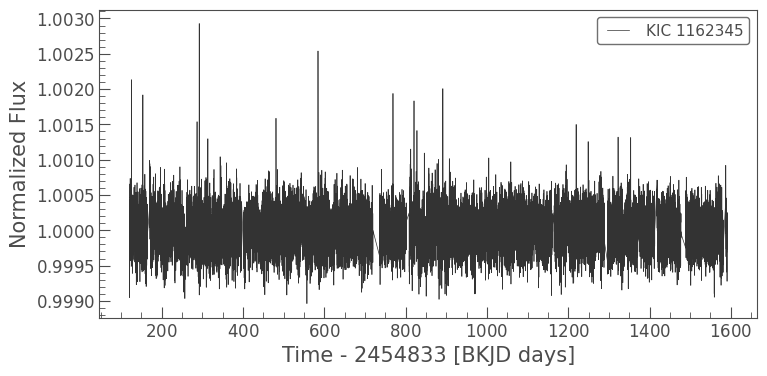

In [31]:
#visualization

lc_clean.plot()